<a href="https://colab.research.google.com/github/IvanDev404/MLPredesneuraisCor.Boys-mlp/blob/main/notebooks/MLPcolabCorBoys.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**1 - 	Apresentação do projeto**

#**2 - Importando as Bibliotecas:**

In [ ]:
!pip install -q datasets pandas sentence-transformers scikit-learn tensorflow matplotlib seaborn


In [ ]:
import pandas as pd
import numpy as np

from datasets import load_dataset

from sentence_transformers import SentenceTransformer

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

import matplotlib.pyplot as plt
import seaborn as sns

#**3 - Carregamento do dataset**

In [ ]:

dataset = load_dataset(
    "bhoomee/SMS_Spam_Multilingual_Collection_Dataset"
)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'labels', 'text', 'text_hi', 'text_de', 'text_fr', 'text_es', 'text_zh', 'text_ar', 'text_bn', 'text_ru', 'text_pt', 'text_ja', 'text_id', 'text_ur', 'text_pa', 'text_jv', 'text_tr', 'text_ko', 'text_mr', 'text_uk', 'text_sv', 'text_no'],
        num_rows: 5572
    })
})


In [ ]:
# Converter os dados para uma tabela Pandas
df = dataset["train"].to_pandas()

# Selecionar somente as colunas que utilizaremos
df = df[["text_pt", "labels"]]

# Renomear as colunas para facilitar o entendimento
df.columns = ["mensagem", "classe"]

# Exibir as primeiras mensagens
display(df.head())

,mensagem,classe
0,"Vai até o ponto jurong, louco.. Disponível ape...",ham
1,Acho que é uma brincadeira que você...,ham
2,Entrada grátis em 2 a wkly comp para ganhar FA...,spam
3,U dun diz tão cedo hor... U c já diz então...,ham
4,"Bem, eu não acho que ele vai para o USF, ele m...",ham


#**4 - Análise Exploratória dos Dados (EDA)**

In [ ]:

# Verificar a quantidade de mensagens e colunas
print("Quantidade de mensagens:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

# Exibir informações gerais
df.info()


Quantidade de mensagens: 5572
Quantidade de colunas: 2
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   mensagem  5572 non-null   object
 1   classe    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:

# Verificar valores ausentes
print("Valores ausentes:")
print(df.isnull().sum())

# Verificar mensagens duplicadas
print("\nMensagens duplicadas:")
print(df.duplicated(subset=["mensagem"]).sum())

# Verificar mensagens vazias
print("\nMensagens vazias:")
print(df["mensagem"].astype(str).str.strip().eq("").sum())


Valores ausentes:
mensagem    0
classe      0
dtype: int64

Mensagens duplicadas:
425

Mensagens vazias:
0


In [ ]:

# Contagem de mensagens por classe
contagem = df["classe"].value_counts()

print(contagem)

# Percentual de cada classe
print("\nPercentual por classe:")
print(df["classe"].value_counts(normalize=True) * 100)


classe
ham     4825
spam     747
Name: count, dtype: int64

Percentual por classe:
classe
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


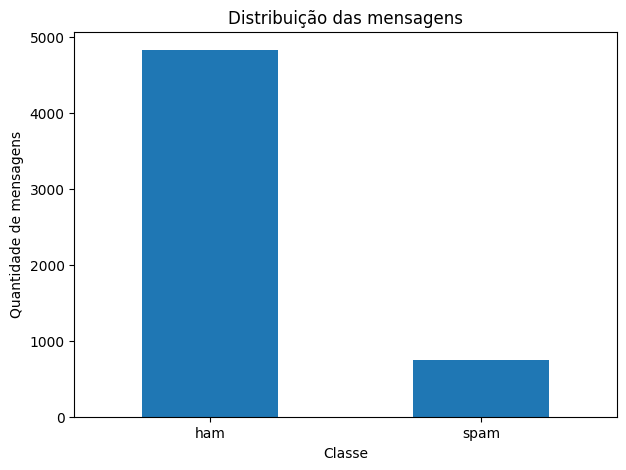

In [ ]:

contagem = df["classe"].value_counts()

plt.figure(figsize=(7, 5))
contagem.plot(kind="bar")

plt.title("Distribuição das mensagens")
plt.xlabel("Classe")
plt.ylabel("Quantidade de mensagens")
plt.xticks(rotation=0)

plt.show()


#**05 - Limpeza e preparação dos dados**

In [ ]:

# Criar uma versão normalizada do texto para comparação
df["mensagem_normalizada"] = (
    df["mensagem"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Identificar mensagens iguais com classificações diferentes
conflitos = (
    df.groupby("mensagem_normalizada")["classe"]
    .nunique()
)

conflitos = conflitos[conflitos > 1]

print("Mensagens com classificações conflitantes:", len(conflitos))


Mensagens com classificações conflitantes: 0


#**06 - Limpeza Final e Codificação**

In [ ]:

# Criar uma cópia para realizar a limpeza
df_limpo = df.copy()

# Remover valores ausentes
df_limpo = df_limpo.dropna(subset=["mensagem", "classe"])

# Remover espaços desnecessários das mensagens
df_limpo["mensagem"] = df_limpo["mensagem"].astype(str).str.strip()

# Padronizar as classes
df_limpo["classe"] = df_limpo["classe"].astype(str).str.strip().str.lower()

# Remover mensagens vazias
df_limpo = df_limpo[df_limpo["mensagem"] != ""]

# Criar coluna auxiliar para identificar duplicatas
df_limpo["mensagem_normalizada"] = (
    df_limpo["mensagem"].str.lower()
)

# Remover mensagens duplicadas
df_limpo = df_limpo.drop_duplicates(
    subset=["mensagem_normalizada"],
    keep="first"
)

# Verificar se existem classes inesperadas
classes_validas = {"ham", "spam"}

if not set(df_limpo["classe"].unique()).issubset(classes_validas):
    raise ValueError("O dataset contém classes inesperadas!")

# Converter as classes para números
df_limpo["classe"] = df_limpo["classe"].map({
    "ham": 0,
    "spam": 1
})

# Remover coluna auxiliar
df_limpo = df_limpo.drop(columns=["mensagem_normalizada"])

# Reiniciar os índices
df_limpo = df_limpo.reset_index(drop=True)

print("Limpeza concluída!")
print("Quantidade de mensagens após limpeza:", len(df_limpo))
print("\nDistribuição das classes:")
print(df_limpo["classe"].value_counts())


Limpeza concluída!
Quantidade de mensagens após limpeza: 5147

Distribuição das classes:
classe
0    4507
1     640
Name: count, dtype: int64


In [ ]:

# Visualizar mensagens após a limpeza
display(df_limpo.head(10))

# Conferir os valores das classes
print("\nClasses disponíveis:")
print(df_limpo["classe"].unique())

# Conferir duplicatas restantes
print("\nDuplicatas restantes:")
print(df_limpo.duplicated(subset=["mensagem"]).sum())


,mensagem,classe
0,"Vai até o ponto jurong, louco.. Disponível ape...",0
1,Acho que é uma brincadeira que você...,0
2,Entrada grátis em 2 a wkly comp para ganhar FA...,1
3,U dun diz tão cedo hor... U c já diz então...,0
4,"Bem, eu não acho que ele vai para o USF, ele m...",0
5,FreeMsg Hey há brincadeira que foi 3 semanas a...,1
6,Mesmo meu irmão não gosta de falar comigo; ele...,0
7,Como por sua solicitação 'Melle Melle (Oru Min...,0
8,WINNER!!Como um cliente de rede valorizado voc...,1
9,Você tem seu celular 11 meses ou mais? U R tem...,1



Classes disponíveis:
[0 1]

Duplicatas restantes:
0


#**07 - Divisão dos Dados (Treino, Validação e Teste)**

In [ ]:

# Separar as mensagens (entrada) e as classes (saída)
X = df_limpo["mensagem"]
y = df_limpo["classe"]

print("Total de mensagens:", len(X))
print("Total de classificações:", len(y))


Total de mensagens: 5147
Total de classificações: 5147


In [ ]:

# Primeira divisão: 70% treino e 30% restante
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Segunda divisão: dividir os 30% restantes em duas partes iguais
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Divisão concluída!")
print("Treinamento:", len(X_treino))
print("Validação:", len(X_validacao))
print("Teste:", len(X_teste))


Divisão concluída!
Treinamento: 3602
Validação: 772
Teste: 773


#**08 - Extração de Embeddings**

In [ ]:

# Carregar o modelo multilíngue
encoder = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

print("Modelo de embeddings carregado com sucesso!")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo de embeddings carregado com sucesso!


In [ ]:

# Converter mensagens de treinamento em embeddings
X_treino_emb = encoder.encode(
    X_treino.tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

# Converter mensagens de validação em embeddings
X_validacao_emb = encoder.encode(
    X_validacao.tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

# Converter mensagens de teste em embeddings
X_teste_emb = encoder.encode(
    X_teste.tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Conversão dos embeddings concluída!")


Batches:   0%|          | 0/113 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Conversão dos embeddings concluída!


In [ ]:

print("Formato dos embeddings:")

print("Treinamento:", X_treino_emb.shape)
print("Validação:", X_validacao_emb.shape)
print("Teste:", X_teste_emb.shape)

# Exibir os primeiros 10 valores do primeiro embedding
print("\nPrimeiros 10 valores do primeiro embedding:")
print(X_treino_emb[0][:10])


Formato dos embeddings:
Treinamento: (3602, 384)
Validação: (772, 384)
Teste: (773, 384)

Primeiros 10 valores do primeiro embedding:
[ 0.02831932 -0.02811513  0.01060842  0.02467451 -0.06857488  0.02587385
 -0.00771897  0.0220322  -0.07342189  0.03731104]


In [ ]:

# Baseline 1: sempre prever a classe mais frequente
baseline_dummy = DummyClassifier(strategy="most_frequent")

baseline_dummy.fit(X_treino_emb, y_treino)

# Baseline 2: Regressão Logística
baseline_logistica = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_logistica.fit(X_treino_emb, y_treino)

print("Baselines treinadas com sucesso!")


Baselines treinadas com sucesso!


#**09 - Criação e Treinamento das Baselines**

In [ ]:

# Fazer previsões
pred_dummy = baseline_dummy.predict(X_teste_emb)
pred_logistica = baseline_logistica.predict(X_teste_emb)

# Avaliar DummyClassifier
print("===== BASELINE DUMMY =====")
print(classification_report(
    y_teste,
    pred_dummy,
    target_names=["NORMAL", "SPAM"],
    zero_division=0
))

# Avaliar Regressão Logística
print("===== BASELINE REGRESSÃO LOGÍSTICA =====")
print(classification_report(
    y_teste,
    pred_logistica,
    target_names=["NORMAL", "SPAM"],
    zero_division=0
))


===== BASELINE DUMMY =====
              precision    recall  f1-score   support

      NORMAL       0.88      1.00      0.93       677
        SPAM       0.00      0.00      0.00        96

    accuracy                           0.88       773
   macro avg       0.44      0.50      0.47       773
weighted avg       0.77      0.88      0.82       773

===== BASELINE REGRESSÃO LOGÍSTICA =====
              precision    recall  f1-score   support

      NORMAL       0.98      1.00      0.99       677
        SPAM       0.99      0.88      0.93        96

    accuracy                           0.98       773
   macro avg       0.99      0.94      0.96       773
weighted avg       0.98      0.98      0.98       773



#**10 - Avaliação Comparativa das Baselines**

In [ ]:

# Definir a arquitetura da MLP
modelo = Sequential([
    Input(shape=(384,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Configurar o treinamento
modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

# Exibir a arquitetura
modelo.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,601 (225.00 KB)

 Trainable params: 57,601 (225.00 KB)

 Non-trainable params: 0 (0.00 B)

#**11 - Construção da Arquitetura MLP**

In [ ]:

# Interromper o treinamento quando não houver melhora
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Treinar a rede neural
historico = modelo.fit(
    X_treino_emb,
    y_treino,
    validation_data=(X_validacao_emb, y_validacao),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Treinamento concluído!")


Epoch 1/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9320 - loss: 0.2118 - precision: 0.8718 - recall: 0.5312 - val_accuracy: 0.9547 - val_loss: 0.1043 - val_precision: 0.7798 - val_recall: 0.8854
Epoch 2/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9814 - loss: 0.0551 - precision: 0.9482 - recall: 0.8996 - val_accuracy: 0.9741 - val_loss: 0.0716 - val_precision: 0.9130 - val_recall: 0.8750
Epoch 3/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9889 - loss: 0.0363 - precision: 0.9700 - recall: 0.9397 - val_accuracy: 0.9754 - val_loss: 0.0724 - val_precision: 0.9140 - val_recall: 0.8854
Epoch 4/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9897 - loss: 0.0301 - precision: 0.9746 - recall: 0.9420 - val_accuracy: 0.9702 - val_loss: 0.0797 - val_precision: 0.8687 - val_recall: 0.8958
Epoch 5/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9953 - loss: 0.0207 - precision: 0.9909 - recall: 0.9710 - val_accuracy: 0.9819 - val_loss: 0.

#**12 - Treinamento da MLP**

In [ ]:
# Obter as probabilidades previstas pelo modelo MLP para o conjunto de teste
probabilidades = modelo.predict(X_teste_emb)

# Converter as probabilidades em classes binárias (0 ou 1)
pred_mlp = (probabilidades > 0.5).astype(int).flatten()

print("Previsões da MLP geradas com sucesso!")

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Previsões da MLP geradas com sucesso!


#**13 - Previsões do Modelo MLP**

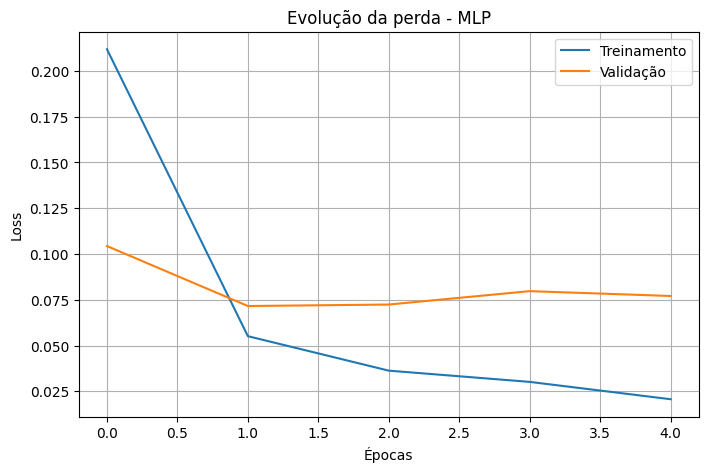

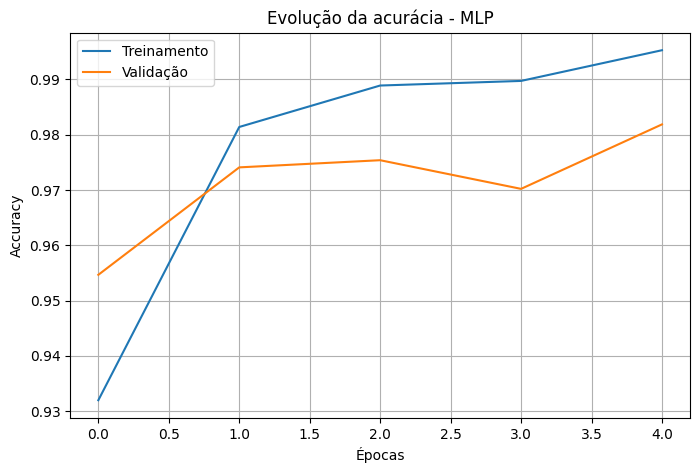

In [ ]:

# Gráfico de perda
plt.figure(figsize=(8, 5))
plt.plot(historico.history["loss"], label="Treinamento")
plt.plot(historico.history["val_loss"], label="Validação")
plt.title("Evolução da perda - MLP")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Gráfico de acurácia
plt.figure(figsize=(8, 5))
plt.plot(historico.history["accuracy"], label="Treinamento")
plt.plot(historico.history["val_accuracy"], label="Validação")
plt.title("Evolução da acurácia - MLP")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


#**14 - Visualização das Métricas de Treino (Loss/Accuracy)**

Matriz de confusão:
[[674   3]
 [  8  88]]


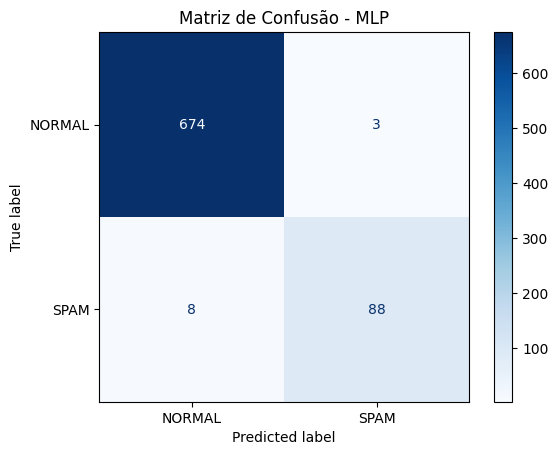

In [ ]:

matriz = confusion_matrix(y_teste, pred_mlp)

print("Matriz de confusão:")
print(matriz)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["NORMAL", "SPAM"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - MLP")
plt.show()


#**15 - Análise dos Erros e Limitações**

In [ ]:
# Organizar os resultados das previsões
analise_erros = pd.DataFrame({
    "mensagem": X_teste.reset_index(drop=True),
    "classe_real": y_teste.reset_index(drop=True),
    "classe_prevista": pred_mlp
})

# Traduzir os rótulos para melhor leitura
analise_erros["classe_real"] = analise_erros["classe_real"].map({
    0: "NORMAL",
    1: "SPAM"
})

analise_erros["classe_prevista"] = analise_erros["classe_prevista"].map({
    0: "NORMAL",
    1: "SPAM"
})

# Selecionar somente as mensagens classificadas incorretamente
erros = analise_erros[
    analise_erros["classe_real"] != analise_erros["classe_prevista"]
]

print("Quantidade de erros:", len(erros))
display(erros)

Quantidade de erros: 11


,mensagem,classe_real,classe_prevista
40,Quer ter um riso? tente CHIT-CHAT no seu celul...,SPAM,NORMAL
70,Estamos felizes em informar que a sua aplicaçã...,NORMAL,SPAM
77,Olá seu LUCY Hubby em reuniões todo o dia Fri ...,SPAM,NORMAL
185,O site não está disponível!,NORMAL,SPAM
217,"Últimas notícias: A polícia roubou o banheiro,...",SPAM,NORMAL
251,Get 2 Burger King antes do 1o de Setembro e vá...,SPAM,NORMAL
471,Você já recebeu seu conteúdo móvel.,SPAM,NORMAL
552,Chame a Alemanha por apenas 1 pence por minuto...,SPAM,NORMAL
683,"Goal! Arsenal 4 (Henry, 7 vs Liverpool 2 Henry...",SPAM,NORMAL
687,Você pode plz me dizer os anos. BSLVYL enviado...,NORMAL,SPAM


#**15 - Demonstração Pratica**

In [ ]:
def classificar_mensagem(mensagem):

    # Transformar a mensagem em embedding
    embedding = encoder.encode(
        [mensagem],
        normalize_embeddings=True
    )

    # Obter a probabilidade de ser spam
    probabilidade = modelo.predict(
        embedding,
        verbose=0
    )[0][0]

    # Classificar a mensagem
    if probabilidade >= 0.5:
        classe = "SPAM"
    else:
        classe = "NORMAL"

    print("Mensagem:", mensagem)
    print("Classificação:", classe)
    print(f"Probabilidade de SPAM: {probabilidade:.2%}")

    return classe

In [ ]:
mensagem = input("Digite uma mensagem SMS: ")

classificar_mensagem(mensagem)